## Setup

In [1]:
import os, json, time, zipfile, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

SEED = 42
keras.utils.set_random_seed(SEED)
keras.mixed_precision.set_global_policy('mixed_float16')
gpus = tf.config.list_physical_devices('GPU'); print('TensorFlow', tf.__version__, '| GPUs:', gpus)
if not gpus: print('WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then run again.')

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/SignSense_data'
WORK, PROC, OUT, MODELS = '/content/work', '/content/processed', '/content/results', '/content/results/models'
for d in (WORK, OUT, MODELS): os.makedirs(d, exist_ok=True)
for f in ['processed_metadata.csv', 'label_map.json', 'class_weights.json', 'channel_stats_train.json']:
    shutil.copy(os.path.join(DRIVE_DIR, f), WORK)

meta = pd.read_csv(f'{WORK}/processed_metadata.csv')
imgs = meta[meta['media_type'] == 'image'].reset_index(drop=True)
imgs['is_generated'] = imgs['is_generated'].astype(bool)
lm = json.load(open(f'{WORK}/label_map.json')); STATIC = lm['static_classes']; N_CLASSES = len(STATIC)
cw = {int(k): v for k, v in json.load(open(f'{WORK}/class_weights.json'))['static'].items()}
st = json.load(open(f'{WORK}/channel_stats_train.json')); MEAN, STD = np.array(st['rgb_mean']), np.array(st['rgb_std'])

def processed_ok(): return os.path.isdir(PROC) and all(os.path.exists(os.path.join(PROC, p)) for p in imgs['processed_path'])
if not processed_ok():
    zp = f'{DRIVE_DIR}/processed_images.zip'
    assert os.path.exists(zp), 'processed_images.zip not found on Drive: run modeling_setup.ipynb first'
    shutil.copy(zp, '/content/processed_images.zip')
    with zipfile.ZipFile('/content/processed_images.zip') as z: z.extractall(PROC)
assert processed_ok(); print('Processed images ready:', len(imgs), '| classes:', N_CLASSES)

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Processed images ready: 21360 | classes: 36


## 1. Load train and validation images into memory
(about 2.7 GB, the test split is deliberately **not** loaded here.)

In [2]:
def load_array(df):
    X = np.empty((len(df), 224, 224, 3), np.uint8)
    paths = [os.path.join(PROC, p) for p in df['processed_path']]
    def f(i): X[i] = cv2.cvtColor(cv2.imread(paths[i]), cv2.COLOR_BGR2RGB)
    with ThreadPoolExecutor(max_workers=8) as ex: list(tqdm(ex.map(f, range(len(df))), total=len(df)))
    return X

tr_df = imgs[imgs['split'] == 'train'].reset_index(drop=True); va_df = imgs[imgs['split'] == 'val'].reset_index(drop=True)
X_tr, y_tr = load_array(tr_df), tr_df['class_id'].values.astype('int32')
X_va, y_va = load_array(va_df), va_df['class_id'].values.astype('int32')
va_orig = ~va_df['is_generated'].values
print('train', X_tr.shape, '| val', X_va.shape, '| val originals:', int(va_orig.sum()))
assert y_tr.min() == 0 and y_tr.max() == N_CLASSES - 1

  0%|          | 0/15062 [00:00<?, ?it/s]

  0%|          | 0/3060 [00:00<?, ?it/s]

train (15062, 224, 224, 3) | val (3060, 224, 224, 3) | val originals: 439


## 2. Data feeder and model builders

In [4]:
class ArrayDS(keras.utils.PyDataset):
    # Training data are reshuffled every epoch and carry class weights
    def __init__(self, X, y, batch=64, shuffle=False, weights=None, seed=SEED):
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=4)
        self.X, self.y, self.batch, self.shuffle, self.weights = X, y, batch, shuffle, weights
        self.idx = np.arange(len(X)); self.rng = np.random.default_rng(seed)
        if shuffle: self.rng.shuffle(self.idx)
    def __len__(self): return int(np.ceil(len(self.X) / self.batch))
    def __getitem__(self, i):
        j = self.idx[i * self.batch:(i + 1) * self.batch]
        x, y = self.X[j].astype('float32'), self.y[j]
        if self.weights is not None: return x, y, np.array([self.weights[c] for c in y], 'float32')
        return x, y
    def on_epoch_end(self):
        if self.shuffle: self.rng.shuffle(self.idx)

train_ds = ArrayDS(X_tr, y_tr, shuffle=True, weights=cw)
val_ds = ArrayDS(X_va, y_va)

def make_augment():
    # Runs on the GPU, active only during training. No horizontal flip (it would turn a right hand into a left hand)
    return keras.Sequential([layers.RandomRotation(0.03, fill_mode='nearest'), layers.RandomTranslation(0.05, 0.05, fill_mode='nearest'),
                             layers.RandomZoom(0.1, fill_mode='nearest'), layers.RandomContrast(0.15),
                             layers.RandomBrightness(0.15, value_range=(0, 255))], name='augment')

def build_baseline():
    inp = keras.Input((224, 224, 3)); x = make_augment()(inp)
    x = layers.Normalization(mean=(MEAN * 255).tolist(), variance=((STD * 255) ** 2).tolist())(x)
    for f in (32, 64, 96, 128, 192):
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(N_CLASSES, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='baseline_cnn'), None

def build_transfer(kind, dropout=0.3):
    inp = keras.Input((224, 224, 3)); x = make_augment()(inp)
    if kind == 'mobilenetv2':
        base = keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3), pooling='avg')
        x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # MobileNetV2 expects [-1, 1]
    else:
        base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(224, 224, 3), pooling='avg')  # Normalizes internally (expects 0-255)
    x = base(x, training=False)                              # BatchNorm always in inference mode
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(N_CLASSES, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name=kind), base

def set_trainable(base, n_last):
    base.trainable = n_last > 0
    for l in base.layers: l.trainable = False
    if n_last > 0:
        for l in base.layers[-n_last:]:
            if not isinstance(l, layers.BatchNormalization): l.trainable = True

## 3. Training and evaluation helpers

In [5]:
def fit_stage(model, lr, epochs, patience, verbose=2):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=verbose).history

def merge(*hists):
    out = {}
    for h in hists:
        for k, v in h.items(): out.setdefault(k, []).extend(v)
    return out

def predict_val(model):
    return np.concatenate([model.predict(X_va[i:i + 128].astype('float32'), verbose=0) for i in range(0, len(X_va), 128)])

def evaluate(model):
    p = predict_val(model).argmax(1)
    return {'val_acc': accuracy_score(y_va, p), 'val_f1': f1_score(y_va, p, average='macro'),
            'val_acc_orig': accuracy_score(y_va[va_orig], p[va_orig]), 'val_f1_orig': f1_score(y_va[va_orig], p[va_orig], average='macro')}

def latency_ms(model, n=40):
    x1 = X_va[:1].astype('float32')
    for _ in range(5): model(x1, training=False)
    t = time.time()
    for _ in range(n): model(x1, training=False).numpy()
    return (time.time() - t) / n * 1000

def save_model(model, name):
    path = f'{MODELS}/{name}.keras'; model.save(path); return os.path.getsize(path) / 1e6

HIST, RESULTS, TUNING = {}, [], []

## 4. Model 1: Baseline CNN (from scratch)
Trained with a higher learning rate and more epochs, since no pre-trained knowledge exists.

In [6]:
t0 = time.time()
model, _ = build_baseline(); print('Parameters (M):', round(model.count_params() / 1e6, 2))
h = fit_stage(model, lr=1e-3, epochs=25, patience=6)
secs = time.time() - t0
HIST['Baseline CNN'] = {'hist': merge(h), 'boundary': None}
r = evaluate(model); size = save_model(model, 'baseline_cnn')
RESULTS.append({'model': 'Baseline CNN', 'params_M': round(model.count_params() / 1e6, 2), 'size_MB': round(size, 1),
                'epochs': len(h['loss']), 'train_min': round(secs / 60, 1), 'latency_ms': round(latency_ms(model), 1), **r})
print(RESULTS[-1]); del model; keras.backend.clear_session()

Parameters (M): 1.03
Epoch 1/25
236/236 - 122s - 517ms/step - accuracy: 0.2539 - loss: 2.5414 - val_accuracy: 0.2324 - val_loss: 3.0910 - learning_rate: 0.0010
Epoch 2/25
236/236 - 95s - 405ms/step - accuracy: 0.7219 - loss: 0.9410 - val_accuracy: 0.7363 - val_loss: 0.8568 - learning_rate: 0.0010
Epoch 3/25
236/236 - 96s - 405ms/step - accuracy: 0.9110 - loss: 0.3612 - val_accuracy: 0.6768 - val_loss: 1.0490 - learning_rate: 0.0010
Epoch 4/25
236/236 - 96s - 405ms/step - accuracy: 0.9537 - loss: 0.1896 - val_accuracy: 0.8647 - val_loss: 0.4207 - learning_rate: 0.0010
Epoch 5/25
236/236 - 95s - 404ms/step - accuracy: 0.9748 - loss: 0.1163 - val_accuracy: 0.8101 - val_loss: 0.5665 - learning_rate: 0.0010
Epoch 6/25
236/236 - 96s - 405ms/step - accuracy: 0.9762 - loss: 0.0998 - val_accuracy: 0.8327 - val_loss: 0.4925 - learning_rate: 0.0010
Epoch 7/25
236/236 - 95s - 405ms/step - accuracy: 0.9871 - loss: 0.0545 - val_accuracy: 0.9294 - val_loss: 0.2994 - learning_rate: 5.0000e-04
Epoch 8/

## 5. Model 2: MobileNetV2 (transfer learning) and tuning
Stage 1 (frozen backbone) is trained once. Then four stage-2 configurations are tried from the same stage-1 weights: **unfrozen layers ∈ {30, 80} × fine-tune learning rate ∈ {1e-4, 3e-5}**.

In [7]:
t0 = time.time()
model, base = build_transfer('mobilenetv2'); print('Parameters (M):', round(model.count_params() / 1e6, 2), '| backbone layers:', len(base.layers))
set_trainable(base, 0)
h1 = fit_stage(model, lr=1e-3, epochs=4, patience=3)
stage1_weights = model.get_weights(); t_stage1 = time.time() - t0
print('Stage 1 done:', {k: round(v[-1], 4) for k, v in h1.items()})

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parameters (M): 2.3 | backbone layers: 155
Epoch 1/4
236/236 - 48s - 202ms/step - accuracy: 0.5375 - loss: 1.6535 - val_accuracy: 0.5843 - val_loss: 1.3119 - learning_rate: 0.0010
Epoch 2/4
236/236 - 34s - 143ms/step - accuracy: 0.8120 - loss: 0.6768 - val_accuracy: 0.6023 - val_loss: 1.1404 - learning_rate: 0.0010
Epoch 3/4
236/236 - 35s - 148ms/step - accuracy: 0.8634 - loss: 0.4886 - val_accuracy: 0.6408 - val_loss: 1.0593 - learning_rate: 0.0010
Epoch 4/4
236/236 - 34s - 145ms/step - accuracy: 0.8947 - loss: 0.3873 - val_accuracy: 0.6699 - val_loss: 0.9809 - learning_rate: 0.0010
Stage 1 done: {'accuracy': 0.8947, 'loss': 0.3873, 'val_accuracy': 0.6699, 'val_loss': 0.9809, 'learning_rate': 0.001}


In [8]:
CONFIGS = {'last30_lr1e-4': (30, 1e-4), 'last30_lr3e-5': (30, 3e-5), 'last80_lr1e-4': (80, 1e-4), 'last80_lr3e-5': (80, 3e-5)}
cfg_weights, cfg_hist = {}, {}
for name, (n_last, lr) in CONFIGS.items():
    t1 = time.time(); print('\n=== config', name, '===')
    model.set_weights(stage1_weights); set_trainable(base, n_last)
    h2 = fit_stage(model, lr=lr, epochs=12, patience=4)
    r = evaluate(model); cfg_weights[name] = model.get_weights(); cfg_hist[name] = merge(h1, h2)
    TUNING.append({'config': name, 'unfrozen_layers': n_last, 'finetune_lr': lr, 'epochs_stage2': len(h2['loss']),
                   'train_min': round((time.time() - t1) / 60, 1), **r})
    print({k: round(v, 4) for k, v in r.items()})
tuning_df = pd.DataFrame(TUNING); tuning_df.round(4)


=== config last30_lr1e-4 ===
Epoch 1/12
236/236 - 47s - 201ms/step - accuracy: 0.9238 - loss: 0.2273 - val_accuracy: 0.7523 - val_loss: 0.7751 - learning_rate: 1.0000e-04
Epoch 2/12
236/236 - 37s - 157ms/step - accuracy: 0.9675 - loss: 0.0952 - val_accuracy: 0.7908 - val_loss: 0.5543 - learning_rate: 1.0000e-04
Epoch 3/12
236/236 - 38s - 162ms/step - accuracy: 0.9785 - loss: 0.0639 - val_accuracy: 0.8225 - val_loss: 0.4785 - learning_rate: 1.0000e-04
Epoch 4/12
236/236 - 38s - 160ms/step - accuracy: 0.9838 - loss: 0.0499 - val_accuracy: 0.8500 - val_loss: 0.4731 - learning_rate: 1.0000e-04
Epoch 5/12
236/236 - 38s - 159ms/step - accuracy: 0.9896 - loss: 0.0340 - val_accuracy: 0.8235 - val_loss: 0.5273 - learning_rate: 1.0000e-04
Epoch 6/12
236/236 - 38s - 162ms/step - accuracy: 0.9888 - loss: 0.0334 - val_accuracy: 0.8539 - val_loss: 0.4769 - learning_rate: 1.0000e-04
Epoch 7/12
236/236 - 38s - 161ms/step - accuracy: 0.9945 - loss: 0.0161 - val_accuracy: 0.8595 - val_loss: 0.5663 - le

,config,unfrozen_layers,finetune_lr,epochs_stage2,train_min,val_acc,val_f1,val_acc_orig,val_f1_orig
0,last30_lr1e-4,30,0.0001,8,5.5,0.8500,0.8385,0.8519,0.8454
1,last30_lr3e-5,30,0.0000,12,8.0,0.8131,0.8061,0.8383,0.8372
2,last80_lr1e-4,80,0.0001,9,7.1,0.9324,0.9310,0.9408,0.9402
3,last80_lr3e-5,80,0.0000,12,9.5,0.8833,0.8794,0.8952,0.8931


In [9]:
best_cfg = tuning_df.sort_values('val_f1', ascending=False).iloc[0]['config']; print('Best MobileNetV2 config (by validation macro-F1):', best_cfg)
model.set_weights(cfg_weights[best_cfg])
HIST['MobileNetV2'] = {'hist': cfg_hist[best_cfg], 'boundary': len(h1['loss'])}
r = evaluate(model); size = save_model(model, 'mobilenetv2')
RESULTS.append({'model': 'MobileNetV2', 'params_M': round(model.count_params() / 1e6, 2), 'size_MB': round(size, 1),
                'epochs': len(cfg_hist[best_cfg]['loss']), 'train_min': round((t_stage1 + tuning_df['train_min'].sum() * 60 / len(tuning_df)) / 60, 1),
                'latency_ms': round(latency_ms(model), 1), **r})
print(RESULTS[-1]); del model, base, cfg_weights, stage1_weights; keras.backend.clear_session()

Best MobileNetV2 config (by validation macro-F1): last80_lr1e-4
{'model': 'MobileNetV2', 'params_M': 2.3, 'size_MB': 26.5, 'epochs': 13, 'train_min': np.float64(10.1), 'latency_ms': 184.8, 'val_acc': 0.9323529411764706, 'val_f1': 0.9309852431105479, 'val_acc_orig': 0.9407744874715261, 'val_f1_orig': 0.9401794336147993}


## 6. Model 3: EfficientNet-B0 (transfer learning)
Same two-stage recipe; the top 40 backbone layers are fine-tuned at learning rate 1e-4.

In [10]:
t0 = time.time()
model, base = build_transfer('efficientnetb0'); print('Parameters (M):', round(model.count_params() / 1e6, 2), '| backbone layers:', len(base.layers))
set_trainable(base, 0); h1 = fit_stage(model, lr=1e-3, epochs=4, patience=3)
set_trainable(base, 40); h2 = fit_stage(model, lr=1e-4, epochs=12, patience=4)
secs = time.time() - t0
HIST['EfficientNet-B0'] = {'hist': merge(h1, h2), 'boundary': len(h1['loss'])}
r = evaluate(model); size = save_model(model, 'efficientnetb0')
RESULTS.append({'model': 'EfficientNet-B0', 'params_M': round(model.count_params() / 1e6, 2), 'size_MB': round(size, 1),
                'epochs': len(h1['loss']) + len(h2['loss']), 'train_min': round(secs / 60, 1), 'latency_ms': round(latency_ms(model), 1), **r})
print(RESULTS[-1]); del model, base; keras.backend.clear_session()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parameters (M): 4.1 | backbone layers: 239
Epoch 1/4
236/236 - 63s - 269ms/step - accuracy: 0.5255 - loss: 1.9623 - val_accuracy: 0.5569 - val_loss: 1.5909 - learning_rate: 0.0010
Epoch 2/4
236/236 - 46s - 194ms/step - accuracy: 0.7852 - loss: 0.9615 - val_accuracy: 0.6157 - val_loss: 1.2392 - learning_rate: 0.0010
Epoch 3/4
236/236 - 46s - 193ms/step - accuracy: 0.8496 - loss: 0.6816 - val_accuracy: 0.6379 - val_loss: 1.0838 - learning_rate: 0.0010
Epoch 4/4
236/236 - 46s - 194ms/step - accuracy: 0.8765 - loss: 0.5539 - val_accuracy: 0.6853 - val_loss: 0.9880 - learning_rate: 0.0010
Epoch 1/12
236/236 - 67s - 282ms/step - accuracy: 0.9328 - loss: 0.2170 - val_accuracy: 0.7918 - val_loss: 0.5282 - learning_rate: 1.0000e-04
Epoch 2/12
236/236 - 50s - 211ms/step - accuracy: 0.9664 - loss: 0.1124 - val_accuracy: 0.8395 - val_loss: 0.3859 - learning_rate: 1.0000e-04
Epoch 3/12
236/236 - 51s - 214ms/step - accuracy: 0.9770 - loss: 0.0754 - 

## 7. Comparison of the three models (validation set)

In [11]:
res = pd.DataFrame(RESULTS)
order = ['model', 'val_acc', 'val_f1', 'val_acc_orig', 'val_f1_orig', 'params_M', 'size_MB', 'latency_ms', 'train_min', 'epochs']
res[order].round(4)

,model,val_acc,val_f1,val_acc_orig,val_f1_orig,params_M,size_MB,latency_ms,train_min,epochs
0,Baseline CNN,0.9278,0.9289,0.9453,0.9442,1.03,20.7,43.5,29.2,18
1,MobileNetV2,0.9324,0.9310,0.9408,0.9402,2.30,26.5,184.8,10.1,13
2,EfficientNet-B0,0.9092,0.9084,0.8838,0.8835,4.10,33.9,313.6,14.3,16


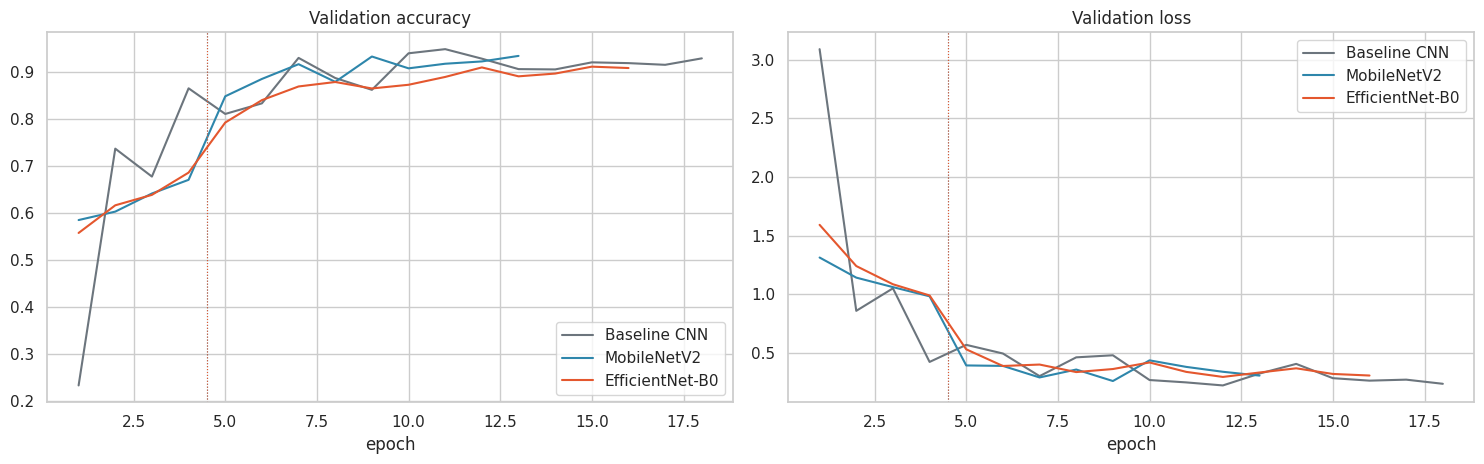

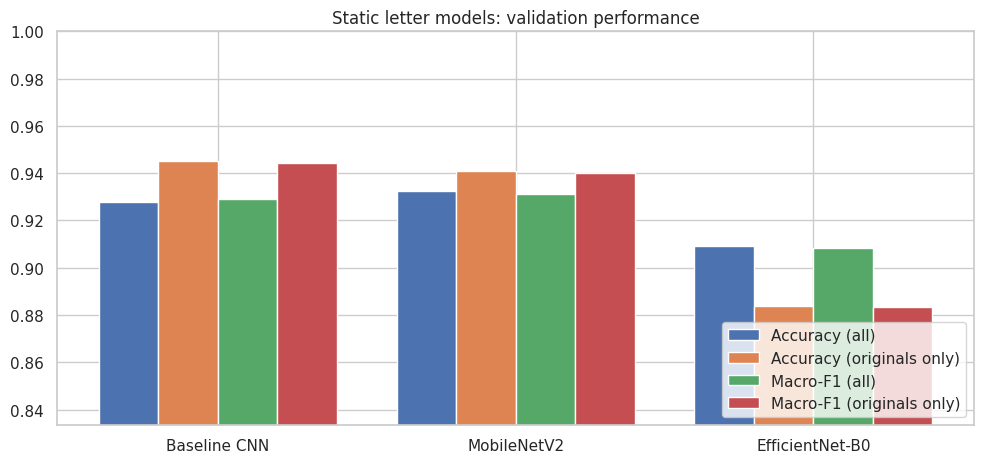

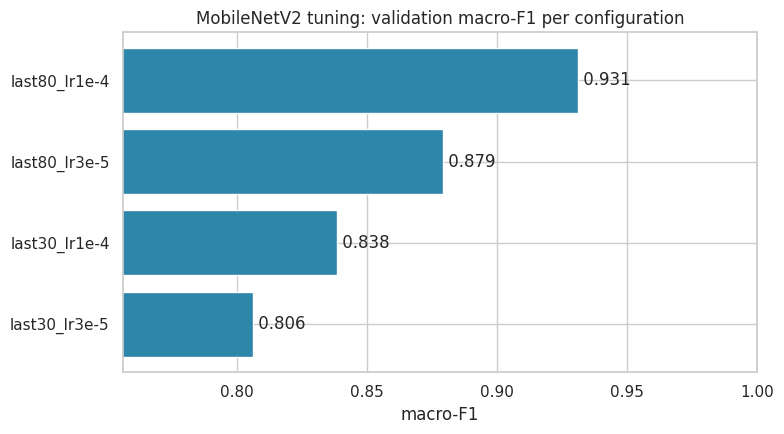

In [12]:
# Figure 1: validation accuracy and loss over epochs (dashed line = start of fine-tuning)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8)); colors = dict(zip(HIST, ['#6c757d', '#2E86AB', '#E4572E']))
for name, d in HIST.items():
    h = d['hist']; ep = np.arange(1, len(h['loss']) + 1)
    axes[0].plot(ep, h['val_accuracy'], label=name, color=colors[name]); axes[1].plot(ep, h['val_loss'], label=name, color=colors[name])
    if d['boundary']:
        for ax in axes: ax.axvline(d['boundary'] + .5, color=colors[name], ls=':', lw=.8)
axes[0].set_title('Validation accuracy'); axes[1].set_title('Validation loss')
for ax in axes: ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/p2_02_static_training_curves.png', dpi=130, bbox_inches='tight'); plt.show()

# Figure 2: model comparison
fig, ax = plt.subplots(figsize=(10, 4.8)); w = 0.2; xs = np.arange(len(res))
for k, (col, lab) in enumerate([('val_acc', 'Accuracy (all)'), ('val_acc_orig', 'Accuracy (originals only)'), ('val_f1', 'Macro-F1 (all)'), ('val_f1_orig', 'Macro-F1 (originals only)')]):
    b = ax.bar(xs + (k - 1.5) * w, res[col], w, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(res['model']); ax.set_ylim(max(0, res[['val_acc', 'val_acc_orig', 'val_f1', 'val_f1_orig']].min().min() - .05), 1.0)
ax.set_title('Static letter models: validation performance'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_03_static_model_comparison.png', dpi=130, bbox_inches='tight'); plt.show()

# Figure 3: MobileNetV2 tuning
fig, ax = plt.subplots(figsize=(8, 4.5)); tb = tuning_df.sort_values('val_f1')
ax.barh(tb['config'], tb['val_f1'], color='#2E86AB'); ax.set_xlim(max(0, tb['val_f1'].min() - .05), 1.0)
for i, v in enumerate(tb['val_f1']): ax.text(v, i, f' {v:.3f}', va='center')
ax.set_title('MobileNetV2 tuning: validation macro-F1 per configuration'); ax.set_xlabel('macro-F1')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_04_mobilenet_tuning.png', dpi=130, bbox_inches='tight'); plt.show()

## 8. Save results and models

In [13]:
res[order].to_csv(f'{OUT}/static_results_val.csv', index=False); tuning_df.to_csv(f'{OUT}/static_tuning_val.csv', index=False)
json.dump({k: v['hist'] for k, v in HIST.items()}, open(f'{OUT}/static_histories.json', 'w'))
# keep copies of the trained models on Drive for the evaluation step
os.makedirs(f'{DRIVE_DIR}/models', exist_ok=True)
for f in os.listdir(MODELS): shutil.copy(f'{MODELS}/{f}', f'{DRIVE_DIR}/models/{f}')
print('Saved to Drive:', os.listdir(f'{DRIVE_DIR}/models'))

Saved to Drive: ['baseline_cnn.keras', 'efficientnetb0.keras', 'mobilenetv2.keras']


In [14]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Final comparison (validation)'); print(res[order].round(4).to_string(index=False))
hdr('MobileNetV2 tuning'); print(tuning_df.round(4).to_string(index=False)); print('Best config:', best_cfg)
hdr('Per-model last epoch values')
for k, d in HIST.items(): print(k, {m: round(v[-1], 4) for m, v in d['hist'].items() if m in ('accuracy', 'val_accuracy', 'loss', 'val_loss')})
hdr('Files to download'); print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))


Final comparison (validation)
          model  val_acc  val_f1  val_acc_orig  val_f1_orig  params_M  size_MB  latency_ms  train_min  epochs
   Baseline CNN   0.9278  0.9289        0.9453       0.9442      1.03     20.7        43.5       29.2      18
    MobileNetV2   0.9324  0.9310        0.9408       0.9402      2.30     26.5       184.8       10.1      13
EfficientNet-B0   0.9092  0.9084        0.8838       0.8835      4.10     33.9       313.6       14.3      16

MobileNetV2 tuning
       config  unfrozen_layers  finetune_lr  epochs_stage2  train_min  val_acc  val_f1  val_acc_orig  val_f1_orig
last30_lr1e-4               30       0.0001              8        5.5   0.8500  0.8385        0.8519       0.8454
last30_lr3e-5               30       0.0000             12        8.0   0.8131  0.8061        0.8383       0.8372
last80_lr1e-4               80       0.0001              9        7.1   0.9324  0.9310        0.9408       0.9402
last80_lr3e-5               80       0.0000          